# Example: A Jump Hidden Markov Model of SPY
In this example, we build a synthetic market for one asset, `SPY`. We fit a hidden Markov model to the daily growth rate of `SPY` from 2014 to 2024, simulate it, and check which features of the real series it reproduces and which it misses. Then we add jump episodes and see what they change.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Fit a hidden Markov model of daily growth rates:__ Bin the daily growth rate into states, estimate the transition matrix by counting, and fit a Student-t distribution to the growth rates in each state.
> * __Check simulated growth rates against the data:__ Compare the distribution, the kurtosis, and the autocorrelation of the absolute growth rate of simulated paths with those of the real series.
> * __Add and tune jump episodes:__ Tune the jump probability and the mean episode length, and explain how jump episodes change volatility clustering.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

> __JumpHMM.jl:__ The [JumpHMM.jl package](https://varnerlab.github.io/JumpHMM.jl/dev/) implements the jump hidden Markov model. The `Include.jl` file imports it with `import JumpHMM`, so we call its functions with the package name in front, for example `JumpHMM.fit(...)`. This keeps them apart from functions with the same names in other packages.

### Data
We load the 2014 to 2024 daily price data with [the `MyTrainingMarketDataSet()` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyTrainingMarketDataSet) and keep the `SPY` closing prices in the `prices::Array{Float64,1}` variable:

In [2]:
prices, dates = let

    # initialize: the daily OHLC data, one DataFrame per ticker -
    dataset = MyTrainingMarketDataSet()["dataset"];
    spy = dataset["SPY"]; # SPY, 2014 to 2024

    # the closing prices and their dates -
    prices = Float64.(spy.close); # USD/share
    dates = spy.timestamp;

    # checks -
    @assert all(prices .> 0) "closing prices must be positive"

    # return -
    (prices, dates)
end;

### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values. We work with the daily growth rate $g_{t} = \frac{1}{\Delta t}\ln\left(S_{t}/S_{t-1}\right)$ (units: 1/yr), with $\Delta t = 1/252$, and compute it with the `JumpHMM.excess_growth_rates(...)` function with no risk-free rate subtracted:

In [3]:
Δt = 1/252; # one trading day, expressed in years
number_of_states = 100; # number of hidden states N, the bins of the growth rate
ν = 5.0; # degrees of freedom of the Student-t distribution in each state
number_of_paths = 200; # number of simulated paths we compare with the data
random_seed = 5660; # fix the random numbers, so every run gives the same paths
number_of_lags = 25; # lags (trading days) of the autocorrelation checks
g = JumpHMM.excess_growth_rates(prices; rf = 0.0, dt = Δt); # daily growth rate of SPY (1/yr)
number_of_days = length(g); # number of growth rates (trading days)

___

## Task 1: Fit the Hidden Markov Model
In this task, we fit the hidden Markov model to the daily growth rate of `SPY`. [The `JumpHMM.fit(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/fitting/) does three things:
* __States:__ It fits a Laplace distribution to the growth rates and cuts it into $N$ bins of equal probability. Each bin is a hidden state, so state 1 holds the most negative growth rates and state $N$ the most positive.
* __Transition matrix:__ It assigns each day to its state and estimates $\hat{p}_{ij}$ by counting the moves from state $i$ to state $j$ on consecutive days, divided by the number of days in state $i$.
* __Emissions:__ In each state, it fits a Student-t distribution, with the location $\mu_{k}$ and the scale $\sigma_{k}$ of the growth rates in that state.

We save the fitted model in the `model::JumpHMM.JumpHiddenMarkovModel` variable:

In [4]:
model = JumpHMM.fit(JumpHMM.JumpHiddenMarkovModel, prices; N = number_of_states, ν = ν, rf = 0.0, dt = Δt);

Let's look at a few of the states. For each one, the table shows its bin of the growth rate (units: 1/yr), the number of days in the training data that fell in the bin, and the location and scale of its Student-t emission:

In [5]:
let

    # initialize: the bin edges and the emissions -
    edges = model.partition.boundaries; # N + 1 edges, from -Inf to +Inf
    states = [1, 2, 25, 50, 75, 99, 100]; # a few states, from the most negative to the most positive

    # one row per state -
    df = DataFrame(state = states, lower = [edges[k] for k ∈ states], upper = [edges[k + 1] for k ∈ states],
        days = [model.emissions[k].n_obs for k ∈ states], μ = [model.emissions[k].μ for k ∈ states],
        σ = [model.emissions[k].σ for k ∈ states]);
    pretty_table(df; column_labels = ["state k", "bin lower (1/yr)", "bin upper (1/yr)", "days", "μ_k (1/yr)", "σ_k (1/yr)"],
        formatters = [fmt__printf("%.3f", [2, 3, 5, 6])], alignment = [:r, :r, :r, :r, :r, :r],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: N bins, and every day lands in exactly one bin -
    @assert length(edges) == number_of_states + 1 "there should be N + 1 bin edges"
    @assert sum(e.n_obs for e ∈ model.emissions) == number_of_days "every day should be counted once"
end

 --------- ------------------ ------------------ ------ ------------ ------------
  state k   bin lower (1/yr)   bin upper (1/yr)   days   μ_k (1/yr)   σ_k (1/yr) 
 --------- ------------------ ------------------ ------ ------------ ------------
        1               -Inf             -6.873     44      -10.130        4.574
        2             -6.873             -5.628     28       -6.191        0.320
       25             -1.167             -1.094     19       -1.131        0.020
       50              0.114              0.150     45        0.132        0.010
       75              1.324              1.395     28        1.365        0.018
       99              5.929              7.174     22        6.341        0.252
      100              7.174                Inf     20       11.307        4.349
 --------- ------------------ ------------------ ------ ------------ ------------


> __What do we see?__ The bins have equal probability under the fitted Laplace distribution, but the Laplace fit is not exact, so the number of days per bin varies. The middle bins are narrow, because most days have small moves. The first and last bins reach out to the crash and rebound days, so their emissions are much wider than those of the middle states.

`Unhide` the code block below to see how we plotted the estimated transition matrix $\hat{\mathbf{P}}$ and compared its stationary distribution $\bar{\pi}$ with how often each state occurred in the data.

> __What do we see?__ The stationary distribution matches the share of days in each state. Most of the structure of $\hat{\mathbf{P}}$ is in its corners: a day in an extreme state is often followed by another day in an extreme state, of either sign, which is volatility clustering over one day.

How is the transition matrix organized?

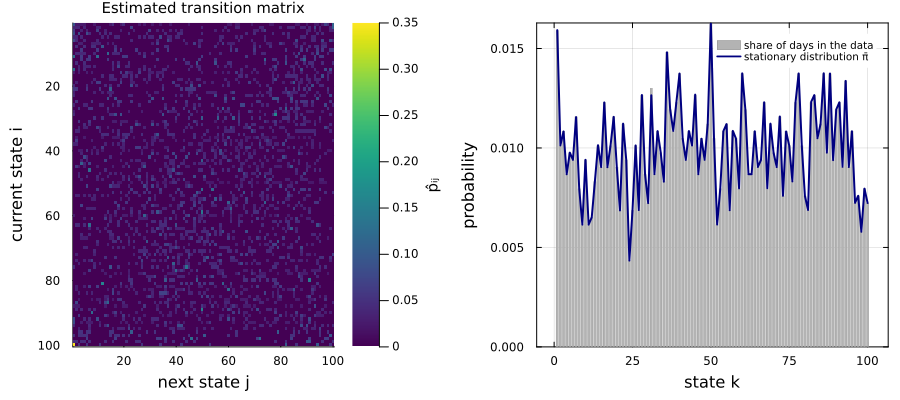

In [6]:
let

    # initialize: the stationary distribution and the empirical share of days in each state -
    states = JumpHMM.assign_states(model.partition, g); # the state of each day
    share = [count(==(k), states) / number_of_days for k ∈ 1:number_of_states]; # empirical share of days in state k
    π̄ = model.stationary; # stationary distribution of the estimated transition matrix

    # plot: the transition matrix, and the stationary distribution against the empirical shares -
    p1 = heatmap(model.transition, c = :viridis, yflip = true, xlabel = "next state j", ylabel = "current state i",
        title = "Estimated transition matrix", titlefontsize = 10, colorbar_title = "p̂ᵢⱼ")
    p2 = plot(1:number_of_states, share, seriestype = :bar, c = :gray70, lw = 0, label = "share of days in the data",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7)
    plot!(p2, 1:number_of_states, π̄, lw = 2, c = :navy, label = "stationary distribution π̄")
    xlabel!(p2, "state k"); ylabel!(p2, "probability")

    # checks: rows of P̂ sum to one, and π̄ = π̄ P̂ -
    @assert all(isapprox.(sum(model.transition; dims = 2), 1.0; atol = 1e-10)) "rows of the transition matrix must sum to one"
    @assert isapprox(π̄' * model.transition, π̄'; atol = 1e-8) "the stationary distribution should satisfy π̄ = π̄P̂"

    plot(p1, p2, layout = (1, 2), size = (900, 400), left_margin = 5Plots.mm, bottom_margin = 5Plots.mm)
end

___

## Task 2: Simulate Without Jumps
In this task, we simulate the fitted model and compare the simulated growth rates with the real ones. [The `JumpHMM.simulate(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/simulation/) starts each path from the stationary distribution, steps the chain with the transition matrix, and draws each day's growth rate from the Student-t emission of the day's state. The fitted model has no jump episodes yet.

We compare three features of the data:
* __Distribution:__ the Kolmogorov–Smirnov test of each simulated path against the real growth rates, and the kurtosis. Consecutive days are not independent, so we read the test as a description of how close the distributions are, not as a formal test.
* __Volatility clustering:__ the autocorrelation of the absolute growth rate $|g_{t}|$ at lags of 1 to 25 trading days. Large moves follow large moves in real data, so this autocorrelation stays positive for weeks.

We save the simulated paths in the `paths_nojump::Array{Float64,2}` variable, one column per path:

In [7]:
paths_nojump = let

    # simulate: number_of_paths paths, each as long as the data -
    result = JumpHMM.simulate(model, number_of_days; n_paths = number_of_paths, seed = random_seed);
    X = hcat([p.observations for p ∈ result.paths]...); # days × paths (1/yr)

    # checks: one column per path, finite growth rates -
    @assert size(X) == (number_of_days, number_of_paths) "unexpected size of the simulated paths"
    @assert all(isfinite, X) "simulated growth rates must be finite"

    # return -
    X
end;

Let's compare the simulated paths with the data. The table shows the standard deviation and kurtosis of the real growth rates and the average over the simulated paths, and the share of paths whose distribution passes the Kolmogorov–Smirnov test at the 5% level:

In [8]:
let

    # initialize: KS p-value of each simulated path against the real growth rates -
    pvalues = [pvalue(ApproximateTwoSampleKSTest(paths_nojump[:, p], g)) for p ∈ 1:number_of_paths];

    # one row per statistic -
    df = DataFrame(statistic = ["standard deviation (1/yr)", "kurtosis (excess)", "share of paths passing KS at 5%"],
        real = [std(g), kurtosis(g), NaN],
        simulated = [mean(std.(eachcol(paths_nojump))), mean(kurtosis.(eachcol(paths_nojump))), mean(pvalues .> 0.05)]);
    pretty_table(df; column_labels = ["statistic", "real SPY", "simulated, no jumps"], alignment = [:l, :r, :r],
        formatters = [fmt__printf("%.3f", [2, 3])], table_format = TextTableFormat(borders = text_table_borders__compact),
        fit_table_in_display_horizontally = false);
end

 --------------------------------- ---------- ---------------------
  statistic                         real SPY   simulated, no jumps 
 --------------------------------- ---------- ---------------------
  standard deviation (1/yr)            2.741                 2.793
  kurtosis (excess)                   13.768                13.137
  share of paths passing KS at 5%        NaN                 0.995
 --------------------------------- ---------- ---------------------


`Unhide` the code block below to see how we plotted the autocorrelation of the absolute growth rate for the data and for the simulated paths.

> __What do we see?__ The simulated paths match the spread and the fat tails of the real growth rates. They miss volatility clustering: their autocorrelation of $|g_{t}|$ is positive at lag 1 but near zero after a few days, while the real one stays positive for weeks. The counted chain forgets a volatile day within a few steps.

How long does volatility cluster?

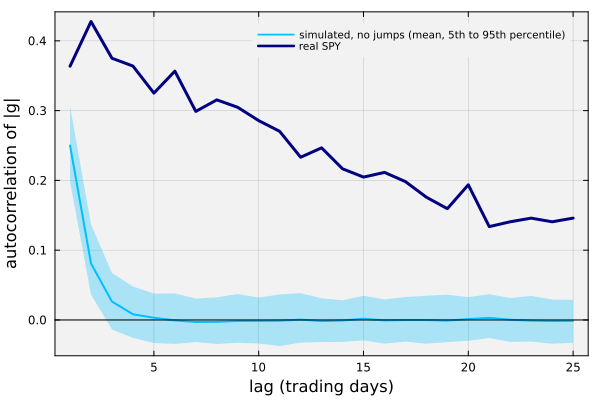

In [9]:
let

    # initialize: autocorrelation of |g| for the data and for each simulated path -
    lags = 1:number_of_lags;
    acf_real = StatsBase.autocor(abs.(g), lags);
    acf_sim = hcat([StatsBase.autocor(abs.(paths_nojump[:, p]), lags) for p ∈ 1:number_of_paths]...); # lags × paths

    # plot: the data, and the middle 90% of the simulated paths -
    lo = [quantile(acf_sim[k, :], 0.05) for k ∈ lags]; hi = [quantile(acf_sim[k, :], 0.95) for k ∈ lags];
    plot(lags, mean(acf_sim; dims = 2), ribbon = (vec(mean(acf_sim; dims = 2)) .- lo, hi .- vec(mean(acf_sim; dims = 2))),
        lw = 2, c = :deepskyblue1, fillalpha = 0.3, label = "simulated, no jumps (mean, 5th to 95th percentile)",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7)
    plot!(lags, acf_real, lw = 3, c = :navy, label = "real SPY")
    hline!([0.0], lw = 1, c = :black, label = "")
    xlabel!("lag (trading days)"); ylabel!("autocorrelation of |g|")
end

___

## Task 3: Add Jump Episodes
In this task, we add jump episodes to restore volatility clustering. On a day with no episode under way, an episode starts with probability $\epsilon$ and lasts a Poisson number of days with mean $\lambda$. On each episode day, the chain draws its state from the most extreme states, negative or positive, so an episode is a run of large moves of both signs.

[The `JumpHMM.tune(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/tuning/) searches a grid of $(\epsilon,\lambda)$ values. For each pair, it simulates paths, keeps the paths that contain an episode, and scores them by the squared error of the autocorrelation of $|g_{t}|$ at lags 1 to 25 plus 0.2 times the squared error of the kurtosis. We use a small grid, so the search runs in class, and save the tuned model in the `tuned_model::JumpHMM.JumpHiddenMarkovModel` variable:

In [10]:
tuned_model = let

    # initialize: a classroom-sized grid of jump probabilities ϵ (per day) and mean episode lengths λ (days) -
    ϵ_range = range(1e-4, 5e-3, length = 6);
    λ_range = range(10.0, 160.0, length = 6);

    # tune: keep the (ϵ, λ) pair with the smallest error -
    time_to_tune = @elapsed tuned_model = JumpHMM.tune(model, prices; ϵ_range = ϵ_range, λ_range = λ_range,
        n_paths = 100, seed = random_seed);
    println("tuned ϵ = $(tuned_model.jump.ϵ) per day, λ = $(tuned_model.jump.λ) days, in $(round(time_to_tune, digits = 1)) s");

    # return -
    tuned_model
end;

tuned ϵ = 0.0001 per day, λ = 100.0 days, in 1.3 s


Let's simulate the tuned model and compare it with the data and with the model without jumps. With a small $\epsilon$, only some paths contain an episode, so we report the paths with an episode separately, as the tuning does. We also report the ratio of the simulated and real standard deviations: the jump episodes add large moves, which can raise the spread above the real one.

In [11]:
paths_jump, has_episode = let

    # simulate the tuned model -
    result = JumpHMM.simulate(tuned_model, number_of_days; n_paths = number_of_paths, seed = random_seed);
    X = hcat([p.observations for p ∈ result.paths]...); # days × paths (1/yr)
    has_episode = [any(p.jumps) for p ∈ result.paths]; # true if the path contains a jump episode
    lags = 1:number_of_lags;
    acf(Y) = vec(mean(hcat([StatsBase.autocor(abs.(Y[:, p]), lags) for p ∈ 1:size(Y, 2)]...); dims = 2)); # mean ACF of |g| over the paths

    # one row per model -
    acf_real = StatsBase.autocor(abs.(g), lags);
    E = X[:, has_episode]; # paths with an episode
    rows = [("real SPY", acf_real, kurtosis(g), 1.0),
            ("no jumps", acf(paths_nojump), mean(kurtosis.(eachcol(paths_nojump))), mean(std.(eachcol(paths_nojump))) / std(g)),
            ("with jumps, paths with an episode", acf(E), mean(kurtosis.(eachcol(E))), mean(std.(eachcol(E))) / std(g))];
    df = DataFrame(model = [r[1] for r ∈ rows], acf1 = [r[2][1] for r ∈ rows], acf5 = [r[2][5] for r ∈ rows],
        acf25 = [r[2][25] for r ∈ rows], kurt = [r[3] for r ∈ rows], sd_ratio = [r[4] for r ∈ rows]);
    pretty_table(df; column_labels = ["", "ACF of |g|, lag 1", "lag 5", "lag 25", "kurtosis", "SD ÷ real SD"],
        alignment = [:l, :r, :r, :r, :r, :r], formatters = [fmt__printf("%.3f", [2, 3, 4, 5, 6])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
    println("share of simulated paths with a jump episode: $(round(mean(has_episode), digits = 2))");

    # checks: at least one path has an episode -
    @assert any(has_episode) "no simulated path contains a jump episode; raise ϵ or the number of paths"

    # return -
    (X, has_episode)
end;

 ----------------------------------- ------------------- ------- -------- ---------- --------------
                                      ACF of |g|, lag 1   lag 5   lag 25   kurtosis   SD ÷ real SD 
 ----------------------------------- ------------------- ------- -------- ---------- --------------
  real SPY                                        0.364   0.325    0.146     13.768          1.000
  no jumps                                        0.250   0.003   -0.001     13.137          1.019
  with jumps, paths with an episode               0.334   0.135    0.102     12.018          1.123
 ----------------------------------- ------------------- ------- -------- ---------- --------------
share of simulated paths with a jump episode: 0.27


> __What do we see?__
>
> * __Volatility clustering:__ On the paths with an episode, the autocorrelation of $|g_{t}|$ stays positive at longer lags, which the model without jumps cannot do. It is still below the real autocorrelation, so the generator reproduces only part of the volatility clustering of `SPY`.
> * __Kurtosis and spread:__ The kurtosis and the standard deviation stay close to the real values. The tuned $\epsilon$ is the smallest value on the grid, so the data tell us only that episodes are rare; frequent episodes would lower the kurtosis.

`Unhide` the code block below to see how we plotted one simulated path with an episode next to the real `SPY` growth rates, with the episode days marked.

What does a path with a jump episode look like?

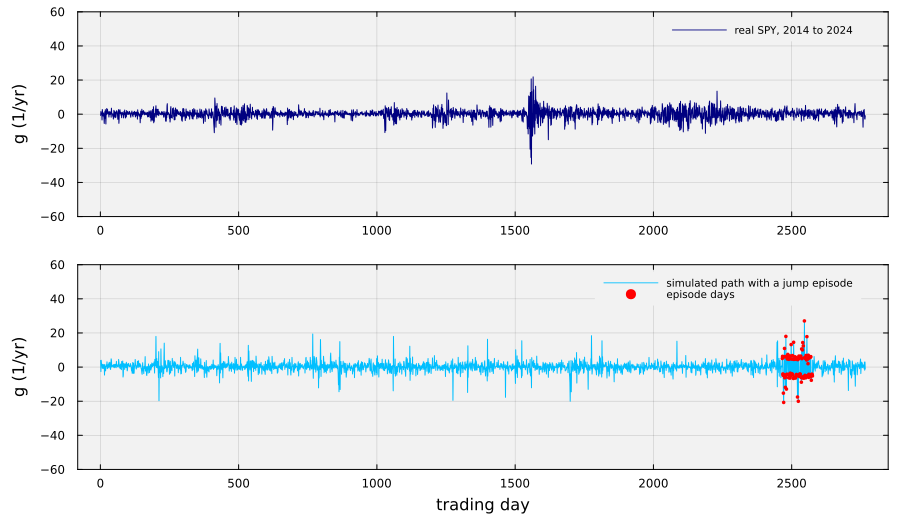

In [12]:
let

    # initialize: the first simulated path with an episode -
    p = findfirst(has_episode);
    result = JumpHMM.simulate(tuned_model, number_of_days; n_paths = number_of_paths, seed = random_seed); # the same paths
    episode = result.paths[p].jumps; # true on the episode days

    # plot: real growth rates, and the simulated path with its episode days marked -
    p1 = plot(1:number_of_days, g, lw = 1, c = :navy, label = "real SPY, 2014 to 2024", ylims = (-60, 60),
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7)
    ylabel!(p1, "g (1/yr)")
    p2 = plot(1:number_of_days, paths_jump[:, p], lw = 1, c = :deepskyblue1, label = "simulated path with a jump episode", ylims = (-60, 60),
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7)
    scatter!(p2, findall(episode), paths_jump[episode, p], ms = 2, msw = 0, c = :red, label = "episode days")
    xlabel!(p2, "trading day"); ylabel!(p2, "g (1/yr)")

    # checks: the plotted path is the stored one -
    @assert result.paths[p].observations == paths_jump[:, p] "the replotted path should match the stored path"

    plot(p1, p2, layout = (2, 1), size = (900, 520), left_margin = 5Plots.mm, bottom_margin = 3Plots.mm)
end

Finally, let's save the tuned model, so the multi-asset example and later lectures can reuse it. We write it to `data/JumpHMM-SPY-2014-2024.jld2` with [the `save(...)` function exported by the JLD2.jl package](https://github.com/JuliaIO/JLD2.jl):

In [13]:
let

    # save the tuned model and the settings it was fit with -
    path = joinpath(_PATH_TO_DATA, "JumpHMM-SPY-2014-2024.jld2");
    save(path, Dict("model" => tuned_model, "N" => number_of_states, "ν" => ν, "Δt" => Δt, "first_date" => first(dates), "last_date" => last(dates)));

    # checks: the file reloads to the same model -
    @assert load(path, "model").jump.λ == tuned_model.jump.λ "the saved model should reload"
end

___

## Summary
In this example, we fit a hidden Markov model to the daily growth rate of `SPY`, simulated it, checked it against the data, and added jump episodes to restore part of the volatility clustering.

> __Key Takeaways:__
>
> * __The hidden Markov model is fit by binning and counting:__ We cut the growth rate into bins of equal probability, estimated the transition matrix by counting moves between bins on consecutive days, and fit a Student-t distribution in each bin. Its stationary distribution matched how often each state occurred in the data.
> * __Without jumps, the model matches the distribution but not the clustering:__ We simulated paths and compared them with the data. They matched the spread and the fat tails of the real growth rates, but their volatility clustering faded within a few days, while the real clustering lasts for weeks.
> * __Jump episodes restore part of the clustering:__ We tuned the probability and the mean length of runs of extreme states. On paths with an episode, the absolute growth rate stayed correlated over longer lags, while the kurtosis and the spread stayed close to the real values.

Understanding how the generator reproduces and misses features of the data lets us judge what a stress test built on it can tell us.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___